# **Homework 02 - Machine Learning - Zoomcamp 2026**

## **Imports**

In [76]:
import pandas as pd
import seaborn as sns
import numpy as np

## **Download car dataset**

In [77]:
DATA_URL =  "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

df_car = pd.read_csv(DATA_URL)

df_car.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## **Preparing the dataset**

In [78]:
df_car = df_car[["engine_displacement", "horsepower", "vehicle_weight", "model_year", "fuel_efficiency_mpg"]]

df_car.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## **EDA**

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

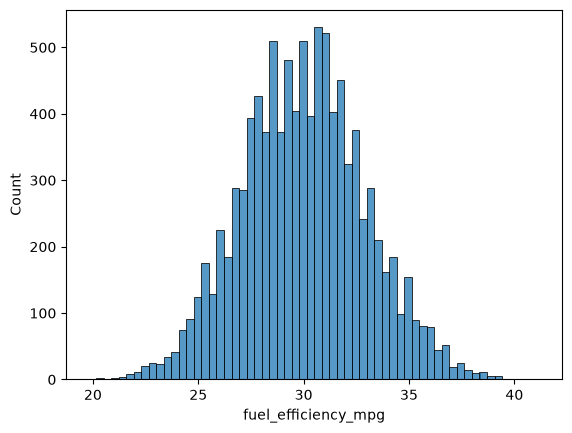

In [79]:
sns.histplot(df_car["fuel_efficiency_mpg"])

The target variable `fuel_efficiency_mpg` has the approximate shape of a bell curve, not a long tail.

## **Question 01**

- **Problem statement: There's one column with missing values. What is it?**

### **Solution**

In [80]:
df_car.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

> **Answer: The `horsepower` column, with a total of 877 missing values.**

## **Question 02**

- **Problem statement: What's the median for variable `horsepower`**

### **Solution**

In [81]:
df_car["horsepower"].median()

np.float64(254.0)

## **Prepare and split the dataset**

In [82]:
def split_dataset(
    df: pd.DataFrame, 
    seed: int=42
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Split a DataFrame into training, validation, and test sets.

    The rows are randomly shuffled before splitting. The validation and
    test sets each receive 20% of the rows, while the remaining rows are
    assigned to the training set.

    Args:
        df: DataFrame to split.
        seed: Random seed used to make the shuffle reproducible.

    Returns:
        A tuple containing the training, validation, and test DataFrames,
        in that order.
    """
    n = len(df)
    n_val = int(0.2 * n)
    n_test = int(0.2 * n)
    n_train = n - n_test - n_val

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    # Reset the shuffled indexes
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    return df_train, df_val, df_test


In [83]:
df_train, df_val, df_test = split_dataset(df_car, 42)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values


del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

## **Question 03**

- **Problem statement: Which imputation on `horsepower` leads to the best RMSE?**

### **Solution**

In [84]:
def normal_equation(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inverse = np.linalg.inv(XTX)
    w_full = XTX_inverse.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def rmse(y_pred, y_actual):
    rmse = np.sqrt(np.mean((y_pred - y_actual) ** 2))
    return np.round(rmse, 3)

- **Fill missing values with 0**

In [85]:
# Training
X_train = df_train.fillna(0).values
w0, w = normal_equation(X_train, y_train)

# Validation
X_val = df_val.fillna(0).values
y_pred = w0 + X_val.dot(w)


print(f"RMSE: {rmse(y_pred, y_val)}")

RMSE: 2.205


- **Fill missing values with the mean**

In [86]:
train_mean = df_train["horsepower"].mean()

# Training
X_train = df_train.fillna(train_mean).values
w0, w = normal_equation(X_train, y_train)

# Validation
X_val = df_val.fillna(train_mean).values
y_pred = w0 + X_val.dot(w)


print(f"RMSE: {rmse(y_pred, y_val)}")

RMSE: 2.202


> **Answer: Filling with the mean shows a better performance.**

## **Question 04**

**Problem statement: Wich `r` gives the best RMSE?**

### **Solution**

In [87]:
def reg_normal_equation(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inverse = np.linalg.inv(XTX)
    w_full = XTX_inverse.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def rmse(y_pred, y_actual):
    rmse = np.sqrt(np.mean((y_pred - y_actual) ** 2))
    return np.round(rmse, 4)

In [88]:
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    # Training
    w0, w = reg_normal_equation(X_train, y_train, r)

    # Validation
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_pred, y_val)

    print(f"\n====== Parameters for r={r} ======")
    print(f" - w0 = {w0}, \n - score = {score}")
    print("===================================")




====== Parameters for r=0 ======
 - w0 = -153.88496188223104, 
 - score = 2.2053

====== Parameters for r=0.01 ======
 - w0 = -148.3092124404723, 
 - score = 2.2058

====== Parameters for r=0.1 ======
 - w0 = -111.83871039307081, 
 - score = 2.2241

====== Parameters for r=1 ======
 - w0 = -32.331865964969374, 
 - score = 2.3492

====== Parameters for r=5 ======
 - w0 = -7.772852209978469, 
 - score = 2.4094

====== Parameters for r=10 ======
 - w0 = -3.987116416019025, 
 - score = 2.4195

====== Parameters for r=100 ======
 - w0 = -0.4082196488463344, 
 - score = 2.4292


> **Answer: r=0.**

## **Question 05**

- **Problem statement: What's the value of std?**

### **Solution**

In [92]:
def rmse(y_pred, y_actual):
    rmse = np.sqrt(np.mean((y_pred - y_actual) ** 2))
    return np.round(rmse, 3)

In [102]:
scores = {}
for seed in np.arange(10):
    df_train, df_val, df_test = split_dataset(df_car, seed=seed)

    y_train = df_train["fuel_efficiency_mpg"].values
    y_val = df_val["fuel_efficiency_mpg"].values
    y_test = df_test["fuel_efficiency_mpg"].values

    del df_train["fuel_efficiency_mpg"]
    del df_val["fuel_efficiency_mpg"]
    del df_test["fuel_efficiency_mpg"]

    X_train = df_train.fillna(0).values
    X_val = df_val.fillna(0).values
    
    w0, w = normal_equation(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    scores[f"seed_{seed}"] = rmse(y_pred, y_val)





In [104]:
df_scores = pd.DataFrame.from_dict(scores, orient='index')
df_scores.rename(columns={0:'RMSE per seed'})

,RMSE per seed
seed_0,2.239
seed_1,2.202
seed_2,2.163
seed_3,2.204
seed_4,2.202
seed_5,2.246
seed_6,2.270
seed_7,2.191
seed_8,2.217
seed_9,2.207


In [107]:
np.round(np.std(df_scores), 3)

np.float64(0.029)

> **Answer: std = 0.029.**

## **Question 06**

- **Problem statement: What's the RMSE on the test dataset?**

### **Solution**

In [115]:
df_train, df_val, df_test = split_dataset(df_car, seed=9)

df_full_train = pd.concat([df_train, df_val], ignore_index=True)

y_full_train = df_full_train["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

del df_full_train["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

X_full_train = df_full_train.fillna(0).values
X_test = df_test.fillna(0).values

w0, w = reg_normal_equation(X_full_train, y_full_train, r=0.001)

y_pred = w0 + X_test.dot(w)

print(f"RMSE: {rmse(y_pred, y_test)}")

RMSE: 2.236


> **Answer: The RMSE on the test set is 2.236.**

[Text(0.5, 1.0, 'Predicted values x actual values on test set'),
 Text(0.5, 0, 'y_test'),
 Text(0, 0.5, 'y_pred')]

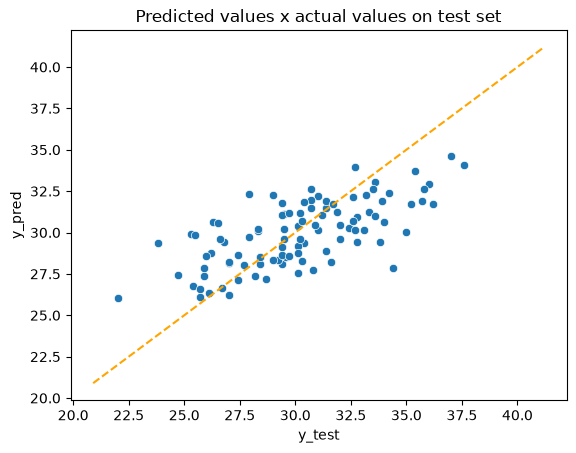

In [125]:
ax = sns.scatterplot(x=y_test[:100], y=y_pred[:100])

lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color="orange", linestyle="--")

ax.set(
    title="Predicted values x actual values on test set",
    xlabel="y_test",
    ylabel="y_pred",
)

In [1]:
stops = {"from": "New York", "to": "Miami"}

a = {**stops}
a

{'from': 'New York', 'to': 'Miami'}

In [6]:
def add_missing_stops(route: dict[str, str], **kwargs):
    """Add missing stops to route dict.

    Parameters:
        route (dict): The dict of routing information.
        (dict): An arbitrary number of stops.

    Returns:
        dict: The updated route dictionary.
    """
    stops_list = list(kwargs.values())
    updated_route = {**route, "stops": [*stops_list]}
    return updated_route

In [7]:
add_missing_stops({"from": "New York", "to": "Miami"},
                      stop_1="Washington, DC", stop_2="Charlotte")

{'from': 'New York', 'to': 'Miami', 'stops': ['Washington, DC', 'Charlotte']}